# Day 15 | Write Clear Prompts

**KGP Talkie**

Give the model a task, useful facts, and a clear answer shape.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [3]:
from pathlib import Path
import os

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [4]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [6]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

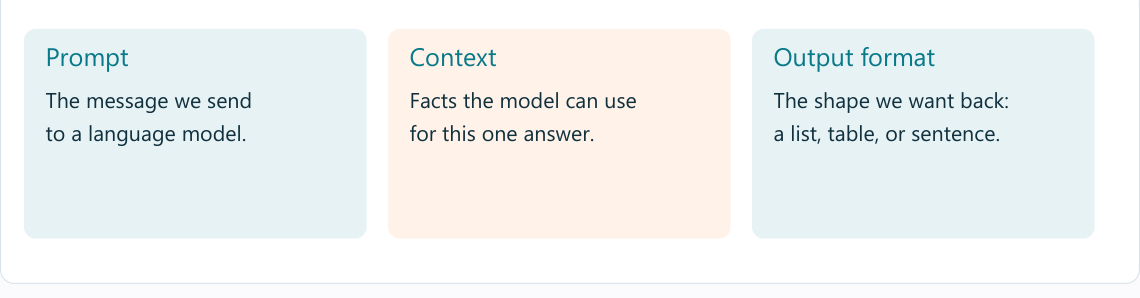

ChatOllama sends chat requests to the local Ollama server.

In [7]:
from langchain_ollama import ChatOllama

We keep tracing off for the local lesson. KGP_MODEL lets us choose another installed chat tag; llama3.2 is the tested default.

In [8]:
os.environ["LANGSMITH_TRACING"] = "false"
MODEL = os.getenv("KGP_MODEL", "llama3.2")

Temperature 0 reduces varied choices. The 128-token cap keeps this small task short; it does not guarantee correctness. localhost means this computer.

In [9]:
llm = ChatOllama(model=MODEL, temperature=0, num_predict=128, base_url="http://localhost:11434", client_kwargs={"timeout": 180})

Context means the exact facts available for this task.

In [10]:
notice = "Python class: Monday at 10:00. Bring a laptop."

This prompt leaves the task and facts unclear. Keep its reply for comparison.

In [11]:
vague = "Tell me about class."

In [13]:
print(llm.invoke(vague).content)

Class can refer to different concepts depending on the context. Here are a few possible meanings:

1. **Social class**: Social class refers to a person's position in society based on their economic, social, and cultural status. It is often categorized into classes such as upper class, middle class, working class, and lower class.
2. **Class (mathematics)**: In mathematics, a class is a set of objects that share certain properties or characteristics. For example, the class of all even numbers or the class of all triangles with specific side lengths.
3. **Class (education)**: In education, a class refers to a


The task, input facts, and answer format are now explicit.

In [14]:
clear = f"Explain this notice in three short bullet points. Use only these facts: {notice}"

In [15]:
print(llm.invoke(clear).content)

Here are three short bullet points explaining the notice:

• A Python class is scheduled for Monday.
• The class starts at 10:00 AM on that day.
• Students should bring their laptops to the class.


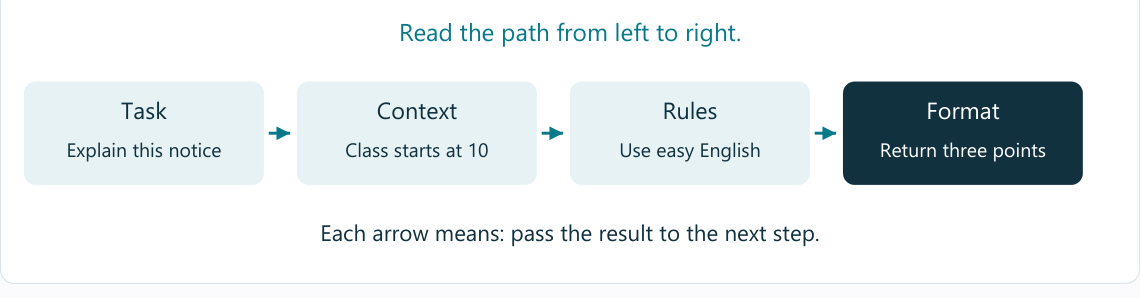

A different notice checks whether the same pattern works beyond one example.

In [16]:
fresh = "Pandas class: Tuesday at 11:00 in Room 3."

In [17]:
print(llm.invoke(f"Explain this notice in one sentence. Use only these facts: {fresh}").content)

There is a scheduled meeting of the Pandas class on Tuesday at 11:00 in Room 3.


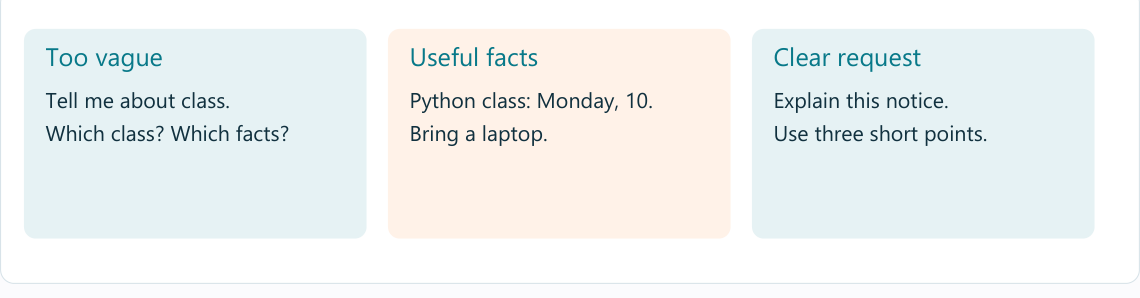

## Try a fresh input

Change only the answer format. See whether the facts stay the same.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/prompt-anatomy).